# Clean-Hour: when is electricity cleanest? (AI + Climate)
Can a forecast tell a household the cleanest hour to charge a car or run the dishwasher, and where does machine learning beat a simple rule like "run at midday"? We test five grids: **Virginia / Mid-Atlantic (our home region)**, California, Texas, Germany and Great Britain. Train 2023-2025, test every day of 2026 (never shuffled).

All numbers below come from the scripts in `src/`; this notebook runs them and shows the outputs.
**Honest scope:** the signal is the *average* carbon intensity of a whole regional grid, not marginal emissions and not one town. Savings are measured against starting at midnight (a deliberately naive baseline).

In [1]:
import os, subprocess, sys
if not os.path.exists("src/multigrid.py"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:  # Colab
        subprocess.run(["git","clone","https://github.com/Harshal623/clean-hour.git"], check=False)
        os.chdir("clean-hour")
subprocess.run([sys.executable,"-m","pip","install","-q","-r","requirements.txt"], check=False)
def run(script, *args):
    r = subprocess.run([sys.executable,"-W","ignore",script,*args], capture_output=True, text=True)
    print(r.stdout[-12000:])
    if r.returncode:
        print("STDERR:", r.stderr[-2000:])
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200)
print(os.getcwd())

C:\Users\Harsh\Downloads\hackathon 1\carbon


## 1. Data: five grids, Jan 2023 to Nov 2026
EIA-930 (Virginia, California, Texas), Energy-Charts (Germany), NESO (Great Britain), Open-Meteo weather forecasts. First run downloads about 400 MB and takes several minutes; later runs use the cache. Missing hours stay missing (never filled).

In [2]:
run("src/grids.py")

pjm   hours 33906  2023-01-01 06:00:00 -> 2026-11-13 23:00:00  missing ci 4  mean ci 345  std 34  weather missing 0
ciso  hours 33903  2023-01-01 09:00:00 -> 2026-11-13 23:00:00  missing ci 24  mean ci 224  std 79  weather missing 0
erco  hours 33905  2023-01-01 07:00:00 -> 2026-11-13 23:00:00  missing ci 24  mean ci 322  std 82  weather missing 0
de    hours 33913  2022-12-31 23:00:00 -> 2026-11-13 23:00:00  missing ci 0  mean ci 310  std 124  weather missing 2
gb    hours 33912  2023-01-01 00:00:00 -> 2026-11-13 23:00:00  missing ci 62  mean ci 133  std 60  weather missing 1



## 2. The deciding test, all five grids
For a 4-hour job decided at 18:00 the evening before, with 12 / 24 / 48 / 72 hours of allowed delay: start at midnight vs persistence vs hour-of-week average vs our model vs perfect hindsight. The model predicts the *change* from the recent same-hour average (our first version predicted the level and was worse than persistence in California; see `results/multigrid_summary_direct.csv`).

In [3]:
run("src/multigrid.py")

target mode: delta

=== Virginia / Mid-Atlantic (USA): test days kept 311 of 314; mean CI 348, std 38 g/kWh
hourly MAE: {'persistence': 21.4, 'climatology': 29.7, 'model': 14.2, 'model_hist': 18.8}
 slip_h  immediate  persistence  climatology  model  oracle  model_pct_saved  oracle_pct_saved
     12      353.4        329.8        342.9  329.2   325.5              6.8               7.9
     24      353.4        330.6        342.6  329.1   324.7              6.9               8.1
     48      353.4        330.6        337.2  323.1   315.8              8.6              10.6
     72      353.4        330.6        331.0  318.1   309.7             10.0              12.4
 slip_h  model_minus_climatology  model_minus_climatology_lo  model_minus_climatology_hi  model_minus_persistence  model_minus_persistence_lo  model_minus_persistence_hi  model_beats_clim_pct_days
     12                    -13.7                       -16.2                       -11.5                     -0.6                 

### Summary tables (from `results/multigrid_summary.csv`)

In [4]:
S = pd.read_csv("results/multigrid_summary.csv")
for sl in (24, 72):
    print(f"--- job can wait {sl} h: gCO2/kWh of the chosen window (lower is better) and % cleaner than starting at midnight")
    x = S[S.slip_h == sl][["name","immediate","persistence","climatology","model","oracle","model_pct_saved","climatology_pct_saved","oracle_pct_saved"]]
    print(x.round(1).to_string(index=False))
    print("model minus hour-of-week rule (g/kWh), 95% block-bootstrap interval; negative = model better")
    print(S[S.slip_h == sl][["name","model_minus_climatology","model_minus_climatology_lo","model_minus_climatology_hi"]].round(1).to_string(index=False))
    print()
print("Great Britain vs NESO's own official forecast (model minus NESO, positive = NESO better):")
print(S[(S.grid=="gb")&S.model_minus_neso.notna()][["slip_h","neso","model","model_minus_neso","model_minus_neso_lo","model_minus_neso_hi"]].round(1).to_string(index=False))

--- job can wait 24 h: gCO2/kWh of the chosen window (lower is better) and % cleaner than starting at midnight
                         name  immediate  persistence  climatology  model  oracle  model_pct_saved  climatology_pct_saved  oracle_pct_saved
Virginia / Mid-Atlantic (USA)      353.4        330.6        342.6  329.1   324.7              6.9                    3.0               8.1
             California (USA)      220.0        100.6        106.3   99.7    97.7             54.7                   51.7              55.6
                  Texas (USA)      338.2        238.6        239.1  237.8   229.8             29.7                   29.3              32.0
                      Germany      364.3        199.6        195.3  194.8   186.4             46.5                   46.4              48.8
                Great Britain      120.0         93.3        115.4   85.5    77.9             28.8                    3.8              35.1
model minus hour-of-week rule (g/kWh), 95% block-

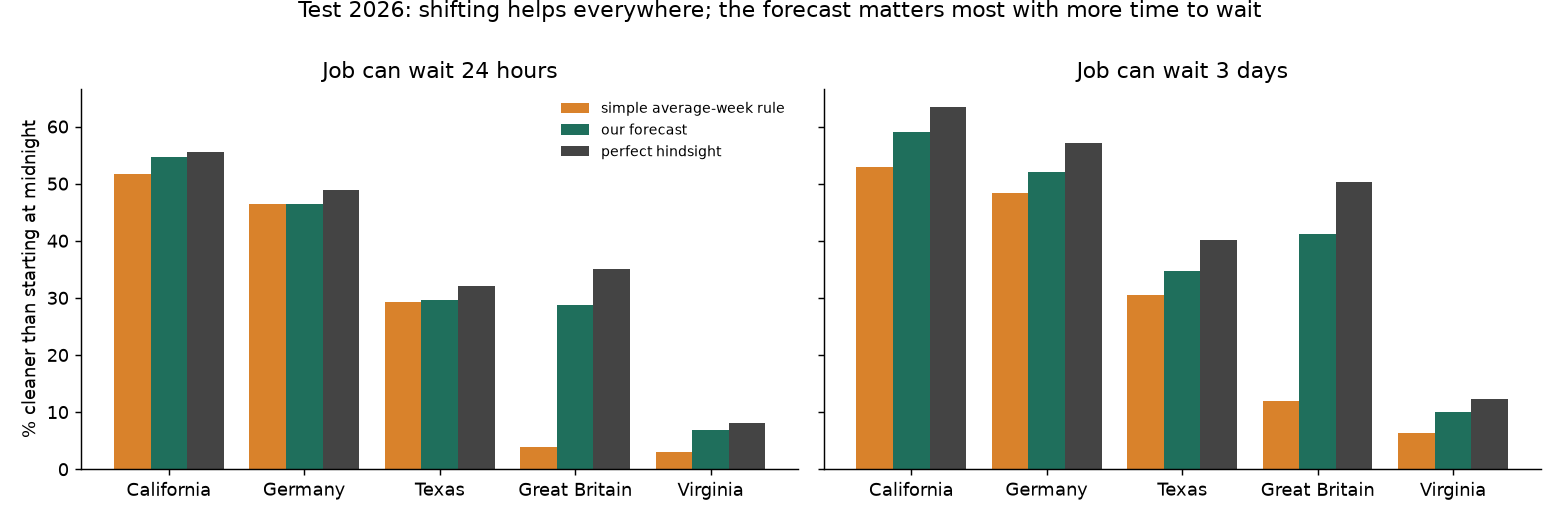

In [5]:
display(Image("results/multigrid_savings.png")) if os.path.exists("results/multigrid_savings.png") else None

## 3. Where it fails (three worst days per region)
Green band = our pick, grey band = best possible window. 12 of the 15 worst days fall in January to March. In Germany, Texas, Britain and Virginia the forecast error on the worst days is well above that region's average; in California it is not (and California's failures are small).

In [6]:
run("src/failures.py")

grid        region  days  median_regret  p90_regret  pct_within_10g_of_best  pct_worse_than_midnight  worst_regret  mean_fcst_err_on_worst3  mean_fcst_err_all
ciso    California   314            0.8         6.1                    96.8                      0.0          21.0                     32.6               33.9
  de       Germany   314            1.1        23.7                    80.9                      5.7         117.2                     72.9               58.4
erco         Texas   314            2.5        19.4                    78.3                      3.2         133.7                     54.9               40.0
  gb Great Britain   314            1.7        26.0                    79.3                     15.3          87.0                     40.7               28.3
 pjm      Virginia   311            2.1        12.8                    87.5                      8.7          43.1                     20.2               13.3
grid        day  model_start  best_start   now

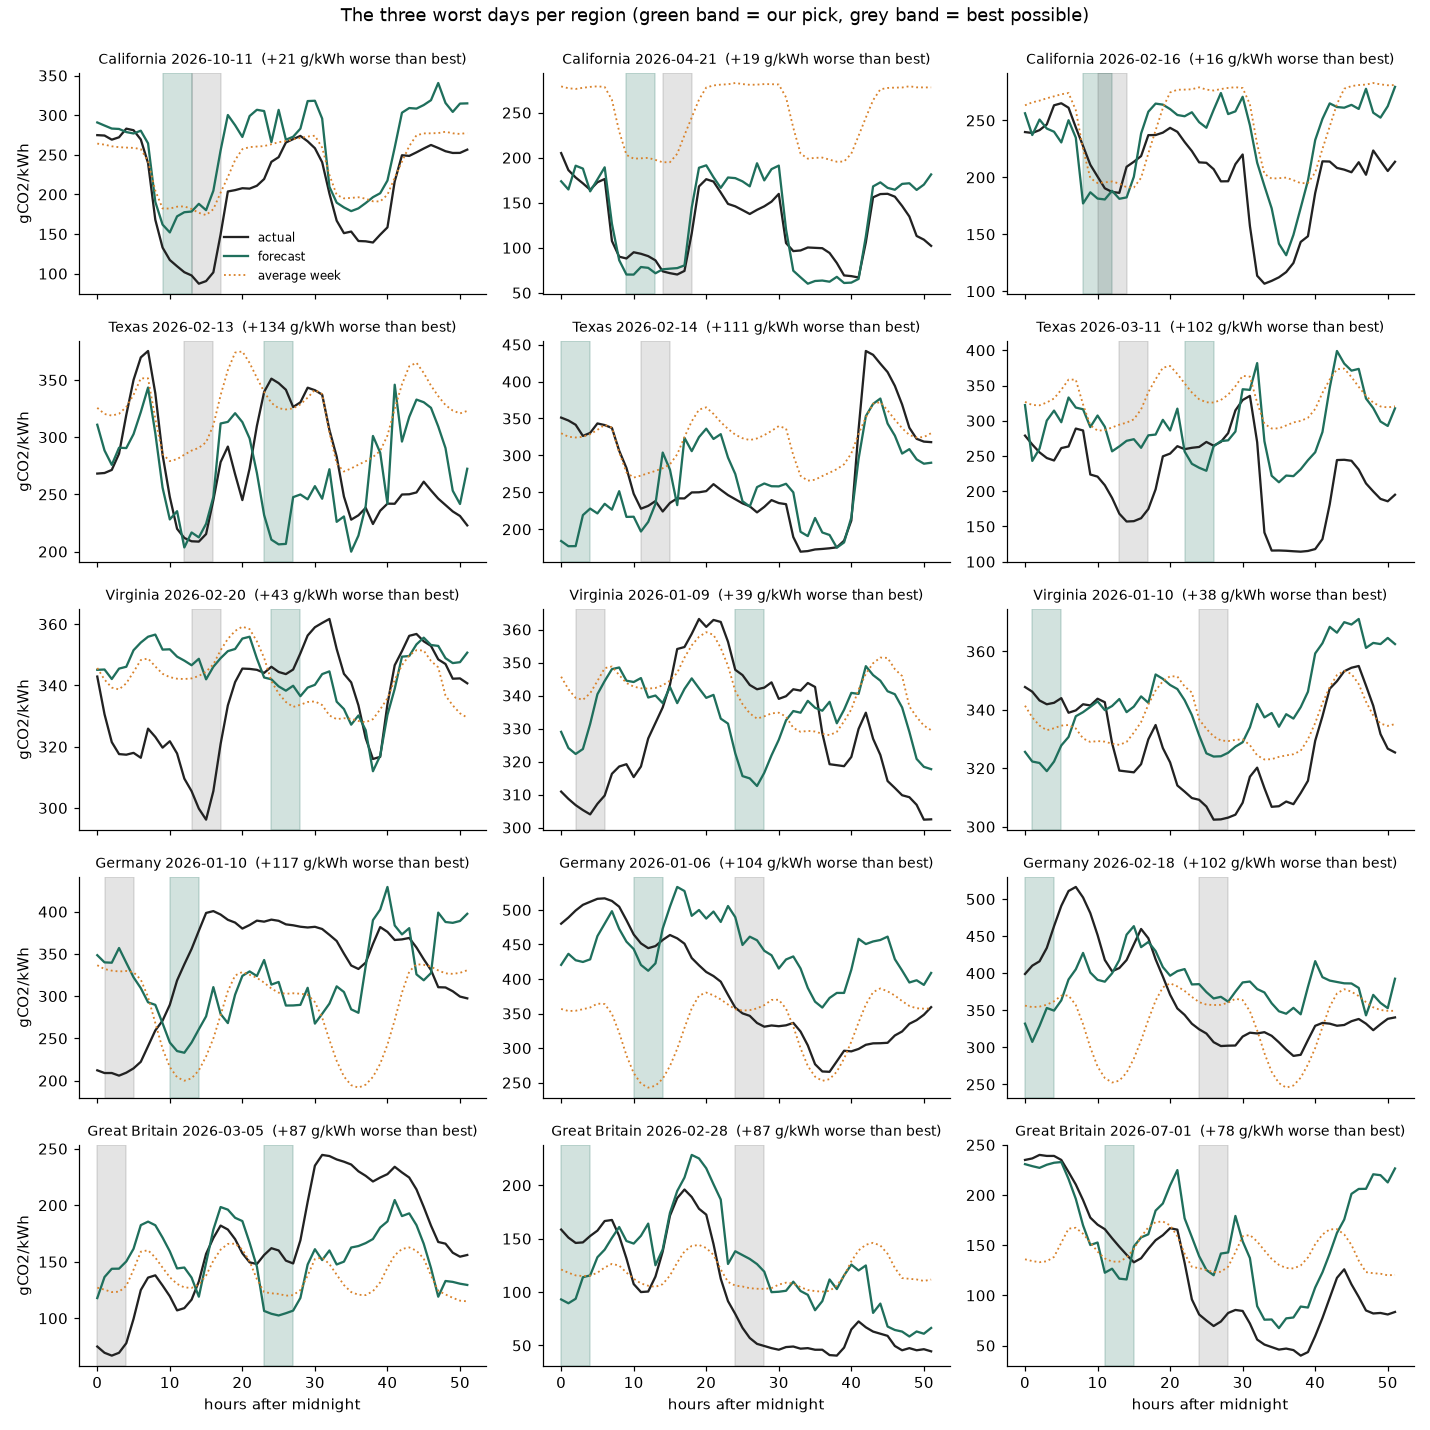

In [7]:
display(Image("results/failures_by_grid.png"))

## 4. Does it survive different emission factors? (`src/sensitivity.py`, about 10 minutes, saved output shown)
We recompute carbon intensity under five emission-factor sets and retrain. Great Britain is excluded because NESO supplies official intensity.

In [8]:
E = pd.read_csv("results/ef_sensitivity_multigrid.csv")
print(E[E.slip_h==24].to_string(index=False))
print("\nrange of model-minus-rule at 24h per grid:"); print(E[E.slip_h==24].groupby("grid").model_minus_clim.agg(["min","max"]).round(1))

grid                        ef_set  slip_h  model_pct_saved  climatology_pct_saved  oracle_pct_saved  model_minus_clim     lo     hi
 pjm      IPCC lifecycle (primary)      24             6.87                   3.04              8.12            -13.51 -15.94 -11.41
 pjm               combustion-only      24             8.31                   3.56              9.48            -16.46 -19.32 -14.21
 pjm gas-heavy (gas 600, coal 900)      24             7.07                   2.98              8.19            -16.87 -19.83 -14.37
 pjm              'other' fuel = 0      24             6.95                   3.04              8.16            -13.60 -16.12 -11.54
 pjm            'other' fuel = 600      24             6.88                   2.90              8.07            -14.44 -17.11 -12.13
ciso      IPCC lifecycle (primary)      24            54.68                  51.70             55.60             -6.56  -8.24  -4.33
ciso               combustion-only      24            67.33          

## 5. What it means for one household (`src/impact.py`, saved output shown)
Kilograms of CO2 avoided per year versus starting at midnight, assuming 3,000 kWh/yr of EV charging and 400 kWh/yr of laundry + dishwasher (our assumptions).

In [9]:
I = pd.read_csv("results/household_impact.csv")
print(I[(I.strategy=="model")&(I.delay_h==24)][["name","load","kg_per_year","kg_per_year_lo","kg_per_year_hi"]].to_string(index=False))

                         name                              load  kg_per_year  kg_per_year_lo  kg_per_year_hi
Virginia / Mid-Atlantic (USA)        EV charging (3,000 kWh/yr)        72.81           64.48           82.33
Virginia / Mid-Atlantic (USA) Laundry + dishwasher (400 kWh/yr)         9.71            8.60           10.98
             California (USA)        EV charging (3,000 kWh/yr)       360.94          321.90          395.93
             California (USA) Laundry + dishwasher (400 kWh/yr)        48.13           42.92           52.79
                  Texas (USA)        EV charging (3,000 kWh/yr)       301.25          282.34          322.34
                  Texas (USA) Laundry + dishwasher (400 kWh/yr)        40.17           37.64           42.98
                      Germany        EV charging (3,000 kWh/yr)       508.42          438.23          594.74
                      Germany Laundry + dishwasher (400 kWh/yr)        67.79           58.43           79.30
                Gre

## 6. Virginia deep dive: a better forecast is not automatically a better choice
From `results/experiments/` (Sidharth's analysis of the saved Virginia forecasts; reproduced here by `src/experiments/decision_stack.py`). A second-stage model trained to rank hours instead of predict levels captures 87-89% of the perfect-foresight saving versus 78-81% for the original model; scored on May-Nov 2026 only because Jan-Apr 2026 was used to train it.

 slip_h                     method  g_per_kWh  saved_vs_run_now_%  captures_%_of_perfect  minus_persistence   mp_lo  mp_hi  minus_model  mm_lo  mm_hi
     12                persistence    330.610               6.855                 88.498              0.000   0.000  0.000       -2.660 -4.071 -1.412
     12                climatology    343.583               3.200                 41.309             12.973  10.319 15.586       10.313  7.522 13.079
     12                      model    333.270               6.105                 78.822              2.660   1.412  4.071        0.000  0.000  0.000
     12         model_history_only    330.721               6.823                 88.095              0.111  -0.679  0.919       -2.549 -4.157 -1.063
     12 average of 3 (no training)    330.576               6.864                 88.620             -0.034  -0.630  0.588       -2.694 -4.034 -1.553
     12           decision stacker    330.342               6.930                 89.472            

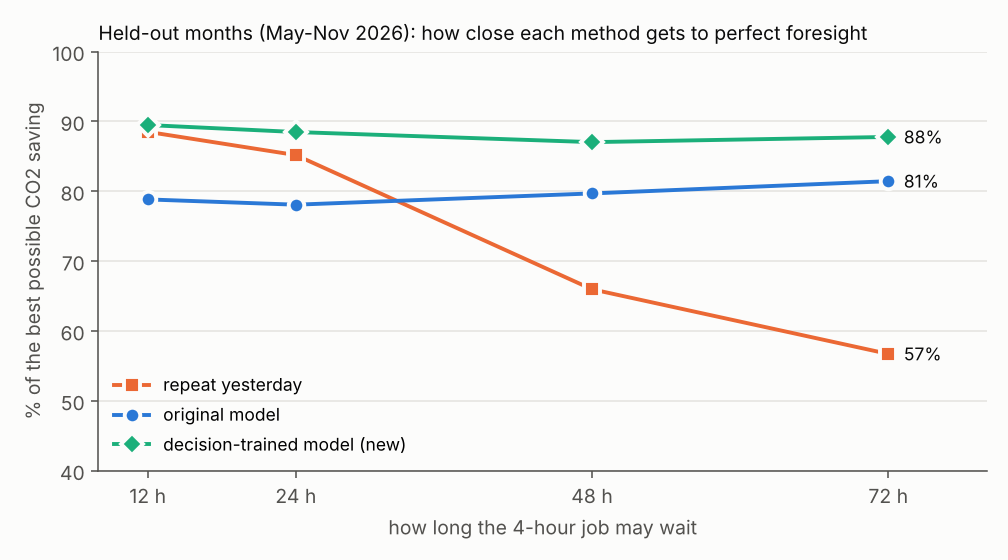

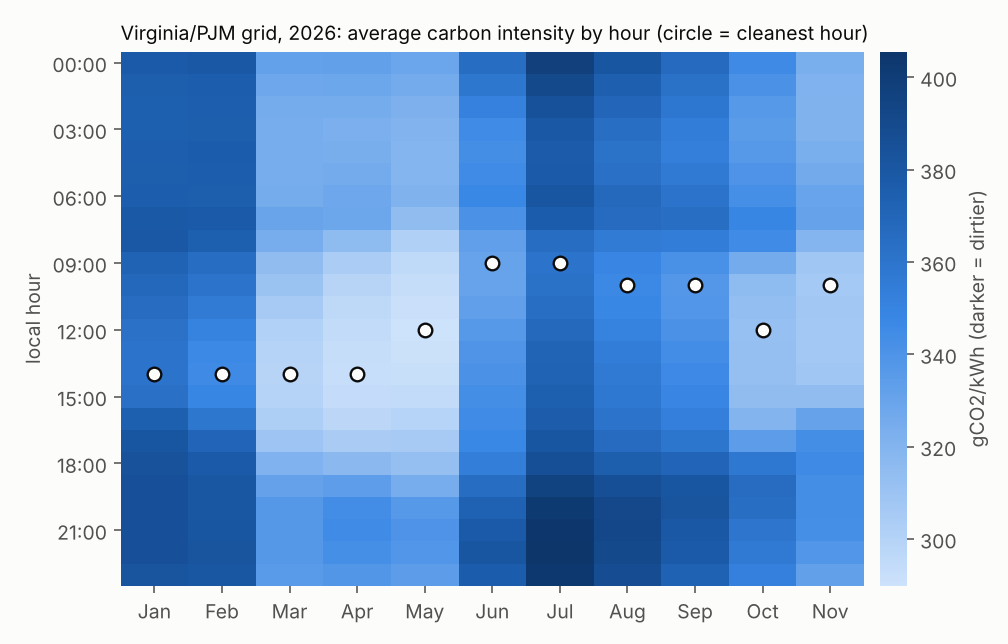

In [10]:
d = pd.read_csv("results/experiments/decision_stack.csv"); print(d.to_string(index=False))
display(Image("results/experiments/capture_vs_flexibility.png")); display(Image("results/experiments/clean_hours_heatmap.png"))

## 7. The app
`python app/app.py` opens the simple household app (pick region, appliance, how long it can wait, and a 2026 day). The older Loudoun data-center analysis is in `notebooks/virginia_deep_dive.ipynb`, `DECISION.md` and `docs/DATA_AUDIT.md`.